# Project 2 - Portfolio Optimization Using Modern Portfolio Theory
**Group Members**
- Luke R.


## What this notebook does
We built a portfolio of **10 publicly traded stocks** and used **Modern Portfolio Theory** to optimize the portfolio. We used the **Sharpe Ratio** to determine the optimal portfolio. We then graph the optimal portfolio and plot the efficient frontier and mark our tangency portfolio.

**The Steps**
1. Download financial data with "yfinance"
2. Turn prices into daily returns, then annualize them.
3. Analyze per-stock return/volatility through a cumulative return plot and a correlation heatmap to justify our decisions.
4. Build thousands of random portfolios, compute the return, volatility, and Sharpe ratio of each one.
5. Pick the optimal portfolio, report the weights, and polt the efficient frontier

# Assumptions
| Item | Choice |
|---|---|
| **Data source** | Daily adjusted close from `yfinance` (with `auto_adjust=True)
| **Data window** | 2021-01-01 to 2026-01-01 (5 years of trading days) 
| **Return type** | Simple daily returns via `pct_change()` 
| **Annualization** | annual return = mean daily return × **252**; annual volatility = daily std × **√252** 
| **Risk-free rate** | rf = 0.03, or 3%
| **Weights** | Long-only portfolio constraint, so all weights must be greater than or equal to 0, and their sum is 1. 

# Step 0: Setup


In [23]:
# Imports modules
#%pip install yfinance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy import stats
from scipy.optimize import minimize
# Makes plots and graphs look better
%matplotlib inline
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["axes.grid"] = True

# Step 1: Choose 10 Tickers and Download Data

In [2]:
#Portfolio returns, volatility, and Sharpe ratios

tickers = ["AAPL", "MCD", "JPM", "AMZN", "JNJ", "TSLA", "NVDA", "AVGO", "KO", "WMT"]

prices = yf.download(tickers, start = "2021-01-01", end = "2026-01-01")
raw = yf.download(tickers, start = "2021-01-01", end = "2026-01-01", auto_adjust=True)
prices = raw["Close"]
prices = prices[tickers]
prices = prices.dropna()
print(prices.tail)

[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  10 of 10 completed<bound method NDFrame.tail of Ticker            AAPL         MCD         JPM        AMZN         JNJ  \
Date                                                                     
2021-01-04  125.740852  186.495712  109.000519  159.331497  134.287369   
2021-01-05  127.295471  187.613510  109.593636  160.925507  135.866211   
2021-01-06  123.010529  187.187668  114.739685  156.919006  137.144730   
2021-01-07  127.208015  188.057083  118.507660  158.108002  137.608093   
2021-01-08  128.306000  191.508057  118.638489  159.134995  137.324905   
...                ...         ...         ...         ...         ...   
2025-12-24  273.302216  311.589386  324.561249  232.380005  205.499420   
2025-12-26  272.893005  308.954102  323.318909  232.520004  205.351074   
2025-12-29  273.252350  306.816040  319.217133  232.070007  205.281830   
2025-12-30  272

# Step 2: Calculate Daily Returns

In [3]:
daily_returns = prices.pct_change().dropna()
prices.head()
daily_returns.head()

Ticker,AAPL,MCD,JPM,AMZN,JNJ,TSLA,NVDA,AVGO,KO,WMT
Date,,,,,,,,,,
2021-01-05,0.012364,0.005994,0.005441,0.010004,0.011757,0.007317,0.022210,0.006773,-0.010993,-0.005323
2021-01-06,-0.033661,-0.002270,0.046956,-0.024897,0.009410,0.028390,-0.058953,-0.006167,-0.031813,0.006244
2021-01-07,0.034123,0.004645,0.032839,0.007577,0.003379,0.079447,0.057830,0.042143,-0.011085,-0.000069
2021-01-08,0.008631,0.018351,0.001104,0.006496,-0.002058,0.078403,-0.005040,0.005074,0.022418,-0.000136
2021-01-11,-0.023249,-0.007597,0.014924,-0.021519,-0.004186,-0.078214,0.025966,0.000269,-0.017228,0.004501


# Step 3: Stock Analysis

## 3a: Past Performance

In [4]:
# Annualized metrics
ann_return = daily_returns.mean() * 252
ann_vol = daily_returns.std() * np.sqrt(252)

# Performance dataframe
performance = pd.DataFrame({
    'Annual Return': ann_return,
    'Annual Volatility': ann_vol
})

# Handle potential divide-by-zero for stocks with zero volatility
performance['Return/Volatility'] = performance['Annual Return'] / performance['Annual Volatility']

# Percentage-formatted view
performance_pct = performance.copy()
performance_pct['Annual Return'] = (performance_pct['Annual Return'] * 100)
performance_pct['Annual Volatility'] = (performance_pct['Annual Volatility'] * 100)
performance_pct['Return/Volatility'] = performance_pct['Return/Volatility']

# Round values for neat display
performance_pct = performance_pct.round({
    'Annual Return': 2,
    'Annual Volatility': 2,
    'Return/Volatility': 2
})

# Sort by the correct existing column name
performance_pct.sort_values('Annual Return', ascending=False)

,Annual Return,Annual Volatility,Return/Volatility
Ticker,,,
NVDA,66.95,52.22,1.28
AVGO,53.12,42.31,1.26
TSLA,30.66,60.74,0.50
JPM,24.45,24.27,1.01
WMT,20.13,20.88,0.96
AAPL,19.32,27.86,0.69
AMZN,13.60,35.11,0.39
MCD,11.29,17.17,0.66
KO,9.94,15.83,0.63


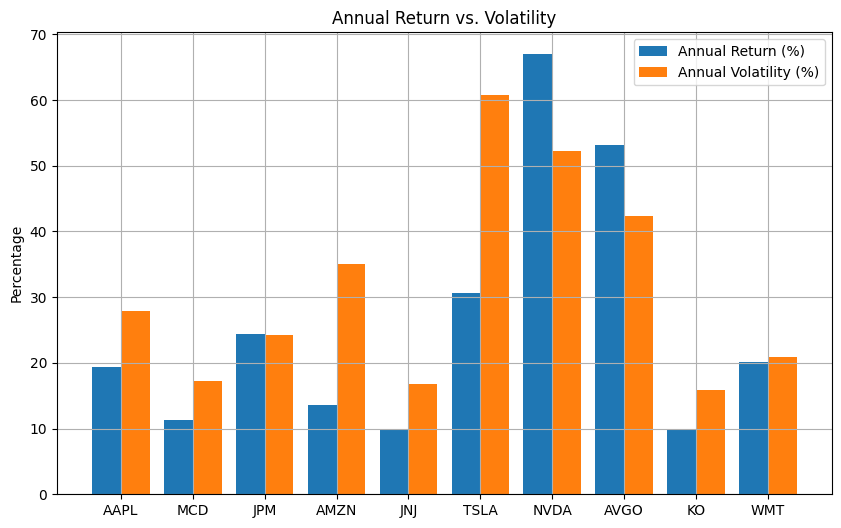

In [5]:
# Bar Chart of Annual Return (%) vs. Volatility (%)
x = np.arange(len(tickers))
width = 0.4

fig, ax = plt.subplots()
ax.bar(x - width/2, ann_return.values * 100, width, label='Annual Return (%)')
ax.bar(x + width/2, ann_vol.values * 100, width, label='Annual Volatility (%)')
ax.set_xticks(x)
ax.set_xticklabels(tickers)
ax.set_ylabel('Percentage')
ax.set_title('Annual Return vs. Volatility')
ax.legend()
plt.show()

## 3b: Cumulative Returns

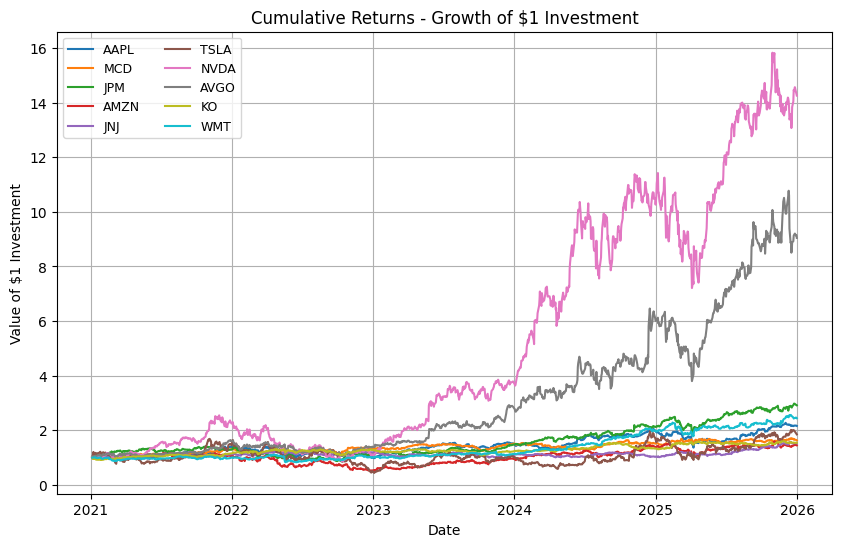

In [6]:
# Growth of $1 Investment
cumulative = (1 + daily_returns).cumprod()

# Plot
fig, ax = plt.subplots()
for t in tickers:
    ax.plot(cumulative.index, cumulative[t], label=t)
ax.set_title('Cumulative Returns - Growth of $1 Investment')
ax.set_xlabel('Date')
ax.set_ylabel('Value of $1 Investment')
ax.legend(ncol = 2, fontsize = 9)
plt.show()

## 3c: Correlation Heatmap

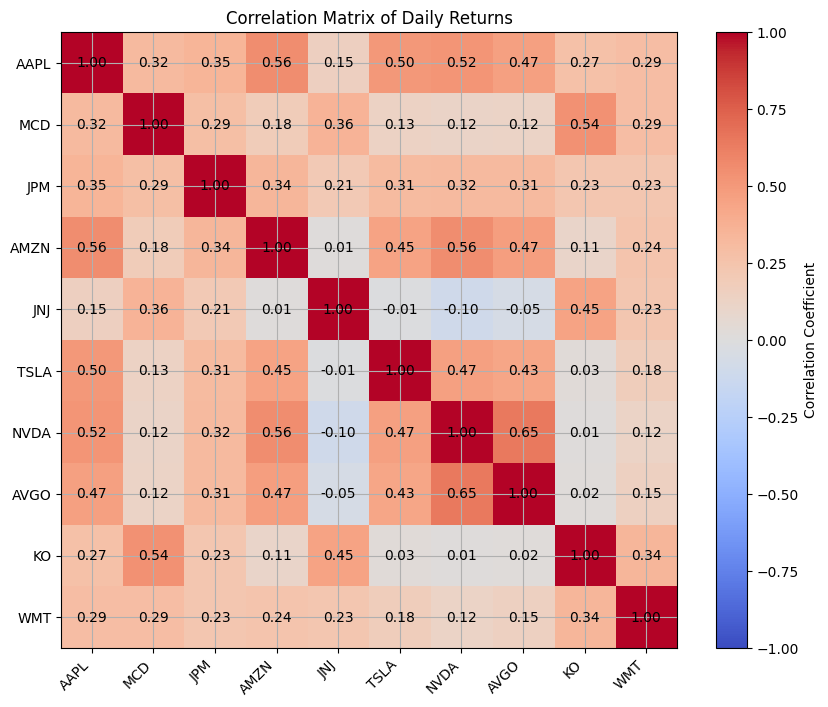

In [7]:
# Correlation of daily returns
corr = daily_returns.corr()
# Plot the correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Add labels and ticks
ax.set_xticks(np.arange(len(tickers)))
ax.set_yticks(np.arange(len(tickers)))
ax.set_xticklabels(tickers, rotation=45, ha='right')
ax.set_yticklabels(tickers)

# Add correlation values to the plot
for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', color='black')
# Add a colorbar/legend
ax.set_title('Correlation Matrix of Daily Returns')
fig.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.tight_layout
plt.show()

# Step 4: Portfolio Optimization

## Step 4a: Define Functions

In [27]:
#defines basic variables
mu = daily_returns.mean() * 252
cov_matrix = daily_returns.cov() * 252
risk_free_rate = 0.03

def portfolio_return(weights, mu): 
    return np.dot(weights, mu)

def portfolio_volatility(weights, cov_matrix): 
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

def sharpe_ratio(weights, mu, cov_matrix, risk_free_rate): 
    port_return = portfolio_return(weights, mu)
    port_volatility = portfolio_volatility(weights, cov_matrix)
    return (port_return - risk_free_rate) / port_volatility

#this function is specifically helpful for plotting the efficient frontier, for minimizing volatility & risk
def min_volatility_for_target_return(target_return, mu, cov_matrix):
    num_assets = len(mu)
    initial_weights = np.ones(num_assets) / num_assets
    bounds = tuple((0, 1) for _ in range(num_assets))  # long-only
    constraints = (
        {"type": "eq", "fun": lambda weights: np.sum(weights) - 1},
        {"type": "eq", "fun": lambda weights: portfolio_return(weights, mu) - target_return}
    )
    result = minimize(
        lambda weights: portfolio_volatility(weights, cov_matrix),
        initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )
    return result

## Step 4b: Monte Carlo simulations and Optimal Weights Table

In [35]:
#Monte Carlo simulations
num_simulations = 1000
results = []
weights_list = []

for i in range(num_simulations): 
    weights = np.random.random(len(tickers))
    weights /= np.sum(weights)    #ensures that all the weights add up to 1
    ret = portfolio_return(weights, mu)
    vol = portfolio_volatility(weights, cov_matrix)
    sharpe = sharpe_ratio(weights, mu, cov_matrix, risk_free_rate)
    results.append([ret, vol, sharpe])
    weights_list.append(weights)


results = pd.DataFrame(results, columns = ["Return", "Volatility", "Sharpe Ratio"])
results.head()

max_sharpe_index = results["Sharpe Ratio"].idxmax()

max_sharpe_portfolio = results.loc[max_sharpe_index]
optimal_weights = weights_list[max_sharpe_index]
optimal_weights_table = pd.DataFrame({"Tickers": tickers, "Optimal Weights (%)": (optimal_weights * 100).round(2)})
optimal_weights_table

,Tickers,Optimal Weights (%)
0,AAPL,6.43
1,MCD,2.13
2,JPM,18.05
3,AMZN,0.15
4,JNJ,18.23
5,TSLA,2.31
6,NVDA,16.82
7,AVGO,15.88
8,KO,2.64
9,WMT,17.36


## Step 4c: Efficient Frontier Plotting with the Maximum Sharpe Portfolio

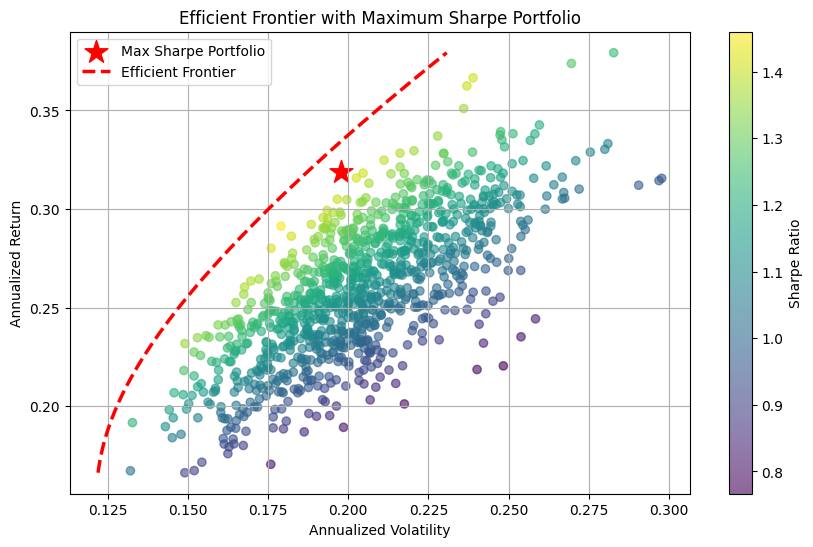

In [29]:
target_returns = np.linspace(results["Return"].min(), results["Return"].max(), 100)
frontier_returns = []
frontier_volatilities = []
for target in target_returns:
    result = min_volatility_for_target_return(target, mu, cov_matrix)
    if result.success:
        frontier_returns.append(target)
        frontier_volatilities.append(result.fun)

plt.figure()
scatter = plt.scatter(results["Volatility"], results["Return"], c = results["Sharpe Ratio"], alpha = 0.6)
plt.colorbar(scatter, label="Sharpe Ratio")
plt.scatter(max_sharpe_portfolio["Volatility"], max_sharpe_portfolio["Return"], marker="*", s=300, c='red', label="Max Sharpe Portfolio")
plt.plot(
    frontier_volatilities,
    frontier_returns,
    "r--",
    linewidth=2.5,
    label="Efficient Frontier"
)
plt.title("Efficient Frontier with Maximum Sharpe Portfolio")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.legend()
plt.grid(True)
plt.show()

# Efficient Frontier Interpretations

The simulated portfolios range from about 12%–30% annualized volatility and roughly 16%–38% annualized return, showing that higher-return portfolios generally require more risk. The maximum-Sharpe portfolio is around 20% volatility and 32% return, with one of the strongest Sharpe ratios on the graph, so it gives a strong balance between risk and return rather than simply maximizing return. The efficient frontier rises above most of the portfolio cloud, meaning many random portfolios are inefficient because they take on similar or higher volatility while earning lower returns. The maximum-Sharpe portfolio had an expected annual return of 31.86%, annualized volatility of 19.77%, and a Sharpe ratio of 1.46. The largest allocations were to WMT, NVDA, JPM, and JNJ, suggesting that the optimal portfolio balanced high-growth stocks such as NVDA with more stable companies such as WMT and JNJ. This supports the idea that the best portfolio is not simply the highest-return portfolio, but the one with the strongest risk-adjusted return.

# Final Optimal Portfolio Results

In [37]:
print("Maximum Sharpe Portfolio")
print("------------------------")
print(f"Expected Annual Return: {max_sharpe_portfolio['Return']:.2%}")
print(f"Annualized Volatility: {max_sharpe_portfolio['Volatility']:.2%}")
print(f"Sharpe Ratio: {max_sharpe_portfolio['Sharpe Ratio']:.2f}")
print("\nOptimal Weights:")
print(optimal_weights_table.to_string(index=False))

Maximum Sharpe Portfolio
------------------------
Expected Annual Return: 31.88%
Annualized Volatility: 19.74%
Sharpe Ratio: 1.46

Optimal Weights:
Tickers  Optimal Weights (%)
   AAPL                 6.43
    MCD                 2.13
    JPM                18.05
   AMZN                 0.15
    JNJ                18.23
   TSLA                 2.31
   NVDA                16.82
   AVGO                15.88
     KO                 2.64
    WMT                17.36


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=d776b066-271e-4246-998a-2a8906bd2384' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>